# Machine Learning Engineer Portfolio Project

## Scope
### Goals
The aim of this proejct is to demonstrate the skills I have developed during the codecadmey Machine Learning/ AI Engineering Career Path.

### Data
The data I will be using is the Chronic Kidney Disease dataset from the UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/336/chronic+kidney+disease

Specific data information is as follows:
1.  Age(numerical) = age in years
2. Blood Pressure(numerical) = bp in mm/Hg
3. Specific Gravity(nominal) = sg - (1.005,1.010,1.015,1.020,1.025)
4. Albumin(nominal) = al - (0,1,2,3,4,5)
5. Sugar(nominal) = su - (0,1,2,3,4,5)
6. Red Blood Cells(nominal) = rbc - (normal,abnormal)
7. Pus Cell (nominal) = pc - (normal,abnormal)
8. Pus Cell clumps(nominal) = pcc - (present,notpresent)
9. Bacteria(nominal) = ba  - (present,notpresent)
10. Blood Glucose Random(numerical) = bgr in mgs/dl
11. Blood Urea(numerical) = bu in mgs/dl
12. Serum Creatinine(numerical)	= sc in mgs/dl
13. Sodium(numerical) = sod in mEq/L
14. Potassium(numerical) = pot in mEq/L
15. Hemoglobin(numerical) = hemo in gms
16. Packed  Cell Volume(numerical)
17. White Blood Cell Count(numerical) = wc in cells/cumm
18. Red Blood Cell Count(numerical)	= rc in millions/cmm
19. Hypertension(nominal) = htn - (yes,no)
20. Diabetes Mellitus(nominal) = dm - (yes,no)
21. Coronary Artery Disease(nominal) = cad - (yes,no)
22. Appetite(nominal) = appet - (good,poor)
23. Pedal Edema(nominal) = pe - (yes,no)	
24. Anemia(nominal) = ane - (yes,no)
25. Class (nominal) = class - (ckd,notckd)

### Analysis
I will develop a machine learning pipeline which handles missing data and fits a model.


In [1]:
# Import the dataset
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
chronic_kidney_disease = fetch_ucirepo(id=336) 
  
# data (as pandas dataframes) 
X = chronic_kidney_disease.data.features 
y = chronic_kidney_disease.data.targets
  
print(X.head())
print(y.head())

    age    bp     sg   al   su     rbc        pc         pcc          ba  \
0  48.0  80.0  1.020  1.0  0.0     NaN    normal  notpresent  notpresent   
1   7.0  50.0  1.020  4.0  0.0     NaN    normal  notpresent  notpresent   
2  62.0  80.0  1.010  2.0  3.0  normal    normal  notpresent  notpresent   
3  48.0  70.0  1.005  4.0  0.0  normal  abnormal     present  notpresent   
4  51.0  80.0  1.010  2.0  0.0  normal    normal  notpresent  notpresent   

     bgr  ...  hemo   pcv    wbcc  rbcc  htn   dm  cad  appet   pe  ane  
0  121.0  ...  15.4  44.0  7800.0   5.2  yes  yes   no   good   no   no  
1    NaN  ...  11.3  38.0  6000.0   NaN   no   no   no   good   no   no  
2  423.0  ...   9.6  31.0  7500.0   NaN   no  yes   no   poor   no  yes  
3  117.0  ...  11.2  32.0  6700.0   3.9  yes   no   no   poor  yes  yes  
4  106.0  ...  11.6  35.0  7300.0   4.6   no   no   no   good   no   no  

[5 rows x 24 columns]
  class
0   ckd
1   ckd
2   ckd
3   ckd
4   ckd


In [2]:
# Import libraries
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier

## ETL
We will look at all the features and their datatypes. I will assess which features should be treated as categorical data and which should be treated as continuous.


In [3]:
print(X.head())
print(X.info())
print(X.nunique())
print(X.dm.unique())

X.dm = X.dm.replace({'\tno':'no'})
print(X.htn.unique())
print(y['class'].unique())

y['class'] = y['class'].replace({'ckd\t':'ckd'})
print(y['class'].unique())

    age    bp     sg   al   su     rbc        pc         pcc          ba  \
0  48.0  80.0  1.020  1.0  0.0     NaN    normal  notpresent  notpresent   
1   7.0  50.0  1.020  4.0  0.0     NaN    normal  notpresent  notpresent   
2  62.0  80.0  1.010  2.0  3.0  normal    normal  notpresent  notpresent   
3  48.0  70.0  1.005  4.0  0.0  normal  abnormal     present  notpresent   
4  51.0  80.0  1.010  2.0  0.0  normal    normal  notpresent  notpresent   

     bgr  ...  hemo   pcv    wbcc  rbcc  htn   dm  cad  appet   pe  ane  
0  121.0  ...  15.4  44.0  7800.0   5.2  yes  yes   no   good   no   no  
1    NaN  ...  11.3  38.0  6000.0   NaN   no   no   no   good   no   no  
2  423.0  ...   9.6  31.0  7500.0   NaN   no  yes   no   poor   no  yes  
3  117.0  ...  11.2  32.0  6700.0   3.9  yes   no   no   poor  yes  yes  
4  106.0  ...  11.6  35.0  7300.0   4.6   no   no   no   good   no   no  

[5 rows x 24 columns]
<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (t

The dm column has a string column with 3 unique values, 'yes', 'no' and '\tno'. We will assume '\tno' is an error of some sort and convert it to 'no'. All other str columns contain 2 unique values so we can assume they are binary inputs.
Although al and su has a float64 data type, these are discrete numbers so will be treated as categorical data in the machine learning pipeline we will create. Therefore, features containing 6 or less unique values will be treated as categorical data for standardisation.

Before creating a pipeline to preprocess the data, the numercial columns are assessed for skewedness in distribution. Some values appear to be skewed so medians will be used to replace missing values.

array([[<Axes: title={'center': 'age'}>, <Axes: title={'center': 'bp'}>,
        <Axes: title={'center': 'bgr'}>],
       [<Axes: title={'center': 'bu'}>, <Axes: title={'center': 'sc'}>,
        <Axes: title={'center': 'sod'}>],
       [<Axes: title={'center': 'pot'}>,
        <Axes: title={'center': 'hemo'}>,
        <Axes: title={'center': 'pcv'}>],
       [<Axes: title={'center': 'wbcc'}>,
        <Axes: title={'center': 'rbcc'}>, <Axes: >]], dtype=object)

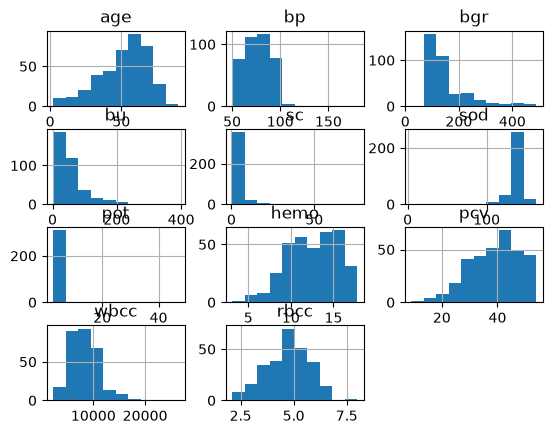

In [4]:
cat_cols = X.columns[X.nunique() <= 6]
num_cols = X.columns[X.nunique() > 7]

X[num_cols].hist()


In [5]:
y = y['class'].replace({'ckd':1, 'notckd':0})

## Model Fitting and Piepline
We have converted the target outcomes for 1 to represent ckd and 0 to represent notckd to fit a logistic regression.

In [21]:
y = y.astype('int')
y = pd.DataFrame({'ckd':y})
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)

In [7]:
cat_vals = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore'))])
num_vals = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])

preprocess = ColumnTransformer(transformers=[
    ('cat_vals', cat_vals, cat_cols),
    ('num_vals', num_vals, num_cols)
])

pipeline1 = Pipeline([('preprocess', preprocess), ('clf', LogisticRegression())])

In [8]:
pipeline1.fit(x_train, y_train)
y_pred = pipeline1.predict(x_test)

print(f'F1 score: {f1_score(y_test, y_pred)}')
print(f'Confusion matrix: \n {confusion_matrix(y_test, y_pred)}')

F1 score: 1.0
Confusion matrix: 
 [[28  0]
 [ 0 52]]


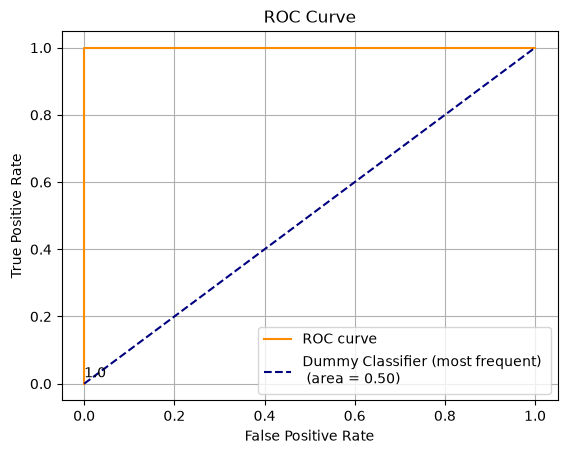

In [9]:
y_pred_prob = pipeline1.predict_proba(x_test)
fpr, tpr, thresholds = roc_curve(y_test,y_pred_prob[:,1])

plt.plot(fpr, tpr, color='darkorange',
         label='ROC curve')

idx = list(range(len(thresholds)))[1::4]
for i in idx:
    plt.text(fpr[i], tpr[i], thresholds[i].round(2))

clf = DummyClassifier(strategy='most_frequent', random_state=0)
clf.fit(x_train, y_train)
roc_auc = roc_auc_score(y_test, clf.predict_proba(x_test)[:,1] )
fpr, tpr, thresholds = roc_curve(y_test, clf.predict_proba(x_test)[:,1])
plt.plot(fpr, tpr, color='navy',linestyle='--', label='Dummy Classifier (most frequent) \n (area = %0.2f)' % roc_auc)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.grid()
plt.legend(loc="lower right")
plt.show()

In [51]:
results = pd.DataFrame(zip(pipeline1.named_steps['preprocess'].get_feature_names_out(), np.transpose(pipeline1.named_steps['clf'].coef_[0])), columns=['features', 'coef'])#.sort_values(by='coef',ascending=False, key=abs)

print(results)
print(len(results)) 



                 features      coef
0       cat_vals__sg_1.01  1.569553
1      cat_vals__sg_1.015  1.156750
2       cat_vals__sg_1.02 -0.986164
3      cat_vals__sg_1.025 -1.786963
4        cat_vals__al_1.0  0.791644
5        cat_vals__al_2.0  0.478416
6        cat_vals__al_3.0  0.671269
7        cat_vals__al_4.0  0.610202
8        cat_vals__al_5.0 -0.000231
9        cat_vals__su_1.0  0.518508
10       cat_vals__su_2.0  0.210957
11       cat_vals__su_3.0  0.196026
12       cat_vals__su_4.0  0.287841
13       cat_vals__su_5.0  0.001157
14   cat_vals__rbc_normal -0.680663
15    cat_vals__pc_normal -0.361461
16  cat_vals__pcc_present  0.187237
17   cat_vals__ba_present  0.136785
18      cat_vals__htn_yes  1.155193
19       cat_vals__dm_yes  1.262870
20      cat_vals__cad_yes  0.055608
21   cat_vals__appet_poor  1.017375
22       cat_vals__pe_yes  0.985875
23      cat_vals__ane_yes  0.169720
24          num_vals__age -0.143822
25           num_vals__bp  0.240793
26          num_vals__bgr  1

In [67]:
def ame_calc(x_test, num_cols, cat_cols):
    ame_num = {}
    ame_cat = {}



    for col in num_cols:
        x_new = x_test.copy()
        x_new[col] += x_test[col].std()

        ame_num[col] = (pipeline1.predict_proba(x_new)[:,1] - pipeline1.predict_proba(x_test)[:,1]).mean()

    ame_num = pd.Series(ame_num, name='AME (%)') * 100

    for col in cat_cols:
        cats = pipeline1.named_steps['preprocess'].named_transformers_['cat_vals'].named_steps['ohe'].categories_[cat_cols.get_loc(col)]

        ref = cats[0]

        x_ref = x_test.copy()
        x_ref[col] = ref

        p_ref = pipeline1.predict_proba(x_ref)[:, 1]

        for cat in cats:
            x_new = x_test.copy()
            x_new[col] = cat

            p_new = pipeline1.predict_proba(x_new)[:,1]

            ame_cat[f'{col}: {cat} vs {ref}'] = (p_new - p_ref).mean() * 100

    ame_cat = pd.Series(ame_cat, name='AME (%)')

    ame = pd.concat([ame_cat, ame_num], axis=0)
    ame = ame[ame !=0]
    ame = ame#.sort_values(ascending = False)
    return ame

ame = ame_calc(x_test, num_cols, cat_cols)
results['features'] = ame.index
results['ame'] = ame.values

results = results.sort_values(by='ame',ascending=False)
print(results)
    

                      features      coef       ame
0            sg: 1.01 vs 1.005  1.569553  6.836286
1           sg: 1.015 vs 1.005  1.156750  4.774344
23               dm: yes vs no  0.169720  3.560726
16              htn: yes vs no  0.187237  3.185634
15                          sc -0.361461  3.048800
33                         bgr  0.138796  2.760308
24         appet: poor vs good -0.143822  2.615943
20               pe: yes vs no  0.055608  2.549929
18              al: 1.0 vs 0.0  1.155193  2.040411
22              al: 3.0 vs 0.0  0.985875  1.701827
4               al: 4.0 vs 0.0  0.791644  1.534450
6               su: 1.0 vs 0.0  0.671269  1.210536
21              al: 2.0 vs 0.0  1.017375  1.182716
25                          bu  0.240793  0.907081
9               su: 4.0 vs 0.0  0.518508  0.652531
7               su: 2.0 vs 0.0  0.610202  0.473910
8                           bp -0.000231  0.461894
34              su: 3.0 vs 0.0 -0.703885  0.439610
10  pcc: present vs notpresent 

## Conclusions
Our model fits the data with an f1 score of 1.0 indicating that it does not inaccurately predict any of the validation data. This is demonstrated in the ROC curve which also has an AUC score of 1.0.

Using the coefficients of the logistic regression model, we calculated the average marginal effect (AME) of each model feature, to predict the average change in predicted probability of chronic kidney disease (CKD) occuring when all other factors are kept constant.

The specific gravity (sg) measures the concentration of solutes in urine, with a higher sg indicating a higher concentration and thus better performing kidneys. The model demonstrates that when sg is low, i.e. 1.01 or 1.015, there is a 4.77% to 6.84% increase in developing CKD wherease a higher sg, i.e. 1.02 or 1.025, has a 3.38 to 6.10% decrease in developing CKD. 

Hypertension (ht) and diabetes myelitus (dm) are to factors associates with a > 3% increase in developing CKD.

Hemoglobin (hemo) levels is associated with a >3% decrease in developing CKD.